# CHLA-Z methods 4: OLCI matchups

**Author:** Eli Holmes (NOAA)<br>
Last updated: November 23, 2026

> **What this notebook is.** One of four *data methods* notebooks for the
> CHLA-Z tables in `datasets/chla_z/data/`. It shows, for one day, exactly how
> the in situ profiles are matched to Sentinel-3 OLCI Level-3 Rrs. It is
> **not** about model training.
>
> **What it is not.** It does not build the tables. The full build runs from
> `datasets/chla_z/build.py`, which calls the same functions in
> `src/chla_z_build.py`. The last section checks the result against the
> released `_plus_OLCI` table.

| # | Notebook | Method | Build stage |
|---|---|---|---|
| 1 | 01-argo-retrieval-qc | BGC-Argo retrieval, QC, depth bins | `argo` |
| 2 | 02-ooi-retrieval-qc | OOI retrieval, QC, 3 h solar-time windows, Sauzède correction | `ooi-fetch`, `ooi` |
| 3 | 03-pace-matchups | PACE Rrs, chlor_a, Kd matchups | `pace`, `pace-merge` |
| 4 | **04-olci-matchups** | Sentinel-3 OLCI Rrs matchups | `olci`, `olci-merge` |

**Why OLCI.** OLCI on Sentinel-3A and 3B gives more valid matchups than
PACE alone, and having both lets you compare sensors on the same profiles.
OLCI is matched to *every* profile, with or without a PACE match, and the
table says whether the profile also has PACE (`pace_granule`,
`pace_Rrs_valid`).

**The rules, in brief** (from Nabir Mamnun's hackweek matchup notebook,
kept so his rows reproduce exactly):

1. NASA OB.DAAC OLCI L3 mapped daily 4 km Rrs, 11 bands (400–709 nm), one
   file per sensor, band and day.
2. The file is the one named for the profile's **UTC calendar day**. (PACE
   uses a 24 h window from the file's start time instead; that difference in
   rule is part of any OLCI vs PACE comparison.)
3. Nearest 4 km cell.
4. S3A first. If any profile of the day has NaN S3A Rrs_443, S3B is read for
   all of the day's profiles, and each band takes S3A where finite, else S3B.
   So the 11 bands of one row can come from both sensors; `olci_sat` names
   the sensor that gave Rrs_443.

Needs a NASA Earthdata login. Runs in about a minute.

In [1]:
import sys

if "../../../src" not in sys.path:
    sys.path.insert(0, "../../../src")

import earthaccess
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import chla_z_build as b

earthaccess.login()

## 1. One day's profiles and files

We use the Argo profiles of 15 July 2025 (OOI works the same way).

In [2]:
ymd = "20250715"
pts = b.olci_points("argo")
sub = pts[pts["ymd"] == ymd].reset_index(drop=True)
print(len(sub), "Argo profiles on", ymd)

69 Argo profiles on 20250715


One search per sensor finds the day's 11 band files. The build makes the
same search for the whole date range once and caches it
(`b.olci_granule_index`).

In [3]:
urls = {}
for sat, sn in b.OLCI_SHORT.items():
    res = earthaccess.search_data(short_name=sn, temporal=(ymd, ymd),
                                  granule_name="*.DAY.*.Rrs_*.4km.nc")
    urls[sat] = {}
    for g in res:
        url = g.data_links(access="external")[0]
        if f".{ymd}.L3m.DAY." in url:
            urls[sat][url.split("Rrs_")[-1].split(".")[0]] = url
    print(sat, sn, len(urls[sat]), "band files")
urls["S3A"]["443"]

S3A OLCIS3A_L3m_ERR_RRS 11 band files


S3B OLCIS3B_L3m_ERR_RRS 11 band files


'https://obdaac-tea.earthdatacloud.nasa.gov/ob-cumulus-prod-public/S3A_OLCI_ERRNT.20250715.L3m.DAY.RRS.Rrs_443.4km.nc'

## 2. Sample S3A, then S3B

`b._olci_sample` opens each band file and reads the nearest cell for every
profile (rule 3).

In [4]:
lats, lons = sub["lat"].to_numpy(), sub["lon"].to_numpy()
s3a = b._olci_sample(urls["S3A"], lats, lons)
need_b = ~np.isfinite(s3a[443])
print(f"S3A Rrs_443 valid for {(~need_b).sum()} of {len(sub)}; S3B needed for {need_b.sum()}")

S3A Rrs_443 valid for 11 of 69; S3B needed for 58


In [5]:
s3b = {nm: np.full(len(sub), np.nan) for nm in b.OLCI_BANDS}
if need_b.any() and urls["S3B"]:
    s3b = b._olci_sample(urls["S3B"], lats, lons)

match = sub[["profile_id"]].copy()
sat = np.full(len(sub), None, dtype=object)
sat[np.isfinite(s3a[443])] = "S3A"
sat[need_b & np.isfinite(s3b[443])] = "S3B"
match["olci_sat"] = sat
for nm in b.OLCI_BANDS:
    match[f"olci_Rrs_{nm}"] = np.where(np.isfinite(s3a[nm]), s3a[nm], s3b[nm])
match["olci_sat"].value_counts(dropna=False)

olci_sat
None    49
S3A     11
S3B      9
Name: count, dtype: int64

Adding S3B nearly doubles the valid matchups on this day: the two sensors'
swaths are interleaved, so S3B covers much of what S3A misses.

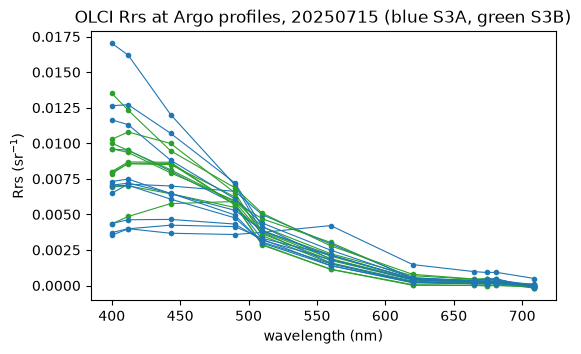

In [6]:
bands = [f"olci_Rrs_{nm}" for nm in b.OLCI_BANDS]
fig, ax = plt.subplots(figsize=(6, 3.5))
for _, r in match.dropna(subset=["olci_sat"]).iterrows():
    ax.plot(b.OLCI_BANDS, r[bands].to_numpy(float), marker=".", lw=0.8,
            color="tab:blue" if r["olci_sat"] == "S3A" else "tab:green")
ax.set_xlabel("wavelength (nm)")
ax.set_ylabel("Rrs (sr$^{-1}$)")
ax.set_title(f"OLCI Rrs at Argo profiles, {ymd} (blue S3A, green S3B)");

The build does this in `b.olci_day_unit(ymd, platform)`, one unit per
(platform, UTC day). One difference from the hackweek notebook: a file that
fails to open raises and the day is retried, rather than being stored as
NaN, so a dropped connection cannot pass for a cloudy pixel.

## 3. Check against the released table

In [7]:
rel = pd.read_parquet(b.DATA_DIR / "CHLA_argo_profiles_plus_OLCI.parquet")
rel = rel[rel["olci_day"] == ymd]
m = rel.merge(match, on="profile_id", suffixes=("_released", ""))
same = all(np.allclose(m[c], m[f"{c}_released"], equal_nan=True) for c in bands)
same_sat = (m["olci_sat"].fillna("") == m["olci_sat_released"].fillna("")).all()
print(f"{len(rel)} released rows on {ymd}, {len(m)} matched here; "
      f"Rrs equal: {same}; olci_sat equal: {same_sat}")
assert len(m) == len(rel) == len(match) and same and same_sat

69 released rows on 20250715, 69 matched here; Rrs equal: True; olci_sat equal: True


The released table also says which of these profiles have PACE:

In [8]:
rel[["pace_granule", "pace_Rrs_valid"]].value_counts()

pace_granule  pace_Rrs_valid
True          False             58
              True              11
Name: count, dtype: int64

## Running the full build

```
cd datasets/chla_z
python build.py olci --workers 6   # ~975 days x 2 platforms, ~80 min
python build.py olci-merge         # -> data/CHLA_{argo,ooi}_profiles_plus_OLCI.parquet
```

`olci-merge` needs the `_plus_PACE` tables first (for the PACE flags). The
released table has a row for every profile on a day with an OLCI file
(through 2026-10-01, the last file at build time), valid or not. Coverage
and the check against Nabir's rows: `claude/notes/chla-z-rebuild-2026-11.md`.